# Results: in-group vs out-group reception of matched posts

**Question.** Are posts with similar content *and* stance received differently within a community depending on whether their author is a member of it?

This notebook walks through the results in the order they were produced. It only reads saved outputs and refits models; it calls no API.

| Part | What | Status |
|---|---|---|
| 1 | Pipeline and data | descriptive |
| 2 | Stance labels | descriptive |
| 3 | Pairs and contrasts | descriptive |
| 4 | **Pre-registered model (PAL–PAL)** | **confirmatory** (`text/analysis_plan.md`) |
| 5 | Plan checks not in `model()` | pre-registered, run separately |
| 6 | ISR–ISR hand check | pre-registered check |
| 7 | ISR–ISR breakdown | exploratory |
| 8 | Exposure-slope sensitivity | exploratory |
| 9 | Community 6 profile | exploratory |
| 10 | Summary | |

Everything after part 6 was decided after seeing the model results, and should be reported as exploratory.

In [1]:
import warnings
import numpy as np
import polars as pl
import statsmodels.api as sm
import matplotlib.pyplot as plt

from bluesky_case_study import reception as r
from bluesky_case_study import isr_check
from bluesky_case_study.paths import DATA_DIR

warnings.filterwarnings("ignore")
pl.Config.set_tbl_rows(50)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_float_precision(2)
pl.Config.set_fmt_str_lengths(60)

polars.config.Config

In [2]:
# Helpers used throughout.

def pooled(df: pl.DataFrame) -> pl.DataFrame:
    # Communities with at least MIN_CONTRASTS contrasts, as in the pre-registered model.
    big = df.group_by("community").len().filter(pl.col("len") >= r.MIN_CONTRASTS)["community"]
    return df.filter(pl.col("community").is_in(big.implode()))


def fit(df: pl.DataFrame, label: str, outcome: str = "reposts", exposure: str = "linear") -> dict:
    # One row of results from the pre-registered conditional model.
    return {"analysis": label, **r.fit_contrasts(df, outcome, exposure)}


def table(rows: list[dict]) -> pl.DataFrame:
    return pl.DataFrame(rows, infer_schema_length=None).select(
        "analysis", "outcome", "contrasts", "communities", "rate_ratio", "ci_low", "ci_high", "p")


def forest(t: pl.DataFrame, title: str, label_col: str = "analysis", ax=None):
    # Rate ratios with 95% CIs on a log scale; 1 = no in-group difference.
    t = t.filter(pl.col("rate_ratio").is_not_null())
    ax = ax or plt.subplots(figsize=(7, 0.42 * t.height + 1.2))[1]
    y = np.arange(t.height)[::-1]
    rr, lo, hi = (t[c].to_numpy() for c in ("rate_ratio", "ci_low", "ci_high"))
    ax.errorbar(rr, y, xerr=[rr - lo, hi - rr], fmt="o", color="#1f4e79", ecolor="#7f9fbf", capsize=3)
    ax.axvline(1, color="grey", lw=1, ls="--")
    ax.set_xscale("log")
    ticks = [t_ for t_ in (0.25, 0.5, 0.75, 1, 1.5, 2, 3, 5, 10, 20)
             if lo.min() / 1.3 <= t_ <= hi.max() * 1.3]
    ax.set_xticks(ticks, [f"{t_:g}" for t_ in ticks])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_yticks(y, t[label_col].to_list())
    ax.set_xlabel("in-group / out-group rate ratio (log scale)")
    ax.set_title(title, loc="left", fontsize=11)
    plt.tight_layout()
    return ax


def fit_slopes(df: pl.DataFrame, outcome: str = "reposts", isr_term: bool = False) -> dict:
    # Exploratory variant: an exposure slope per community instead of one shared slope.
    # Same conditional binomial model and two-way clustered SEs as reception.fit_contrasts.
    d = r._design(df).filter((pl.col(f"in_{outcome}") + pl.col(f"out_{outcome}")) > 0)
    cs = d["community"].to_numpy()
    cols, names = [np.ones(d.height)], ["in-group"]
    if isr_term:
        cols.append((d["side_pair"] == "ISR-ISR").to_numpy().astype(float))
        names.append("ISR vs PAL")
    fc, fa = d["d_log_fc"].to_numpy(), d["d_log_fall"].to_numpy()
    for c in np.unique(cs):
        m = (cs == c).astype(float)
        if m.sum() >= 30:
            cols += [fc * m, fa * m]
    cols.append(d["d_age"].to_numpy() / 30)
    X = np.column_stack(cols)
    X = X[:, np.r_[[True] * len(names), X[:, len(names):].std(0) > 0]]
    y = np.column_stack([d[f"in_{outcome}"].to_numpy(), d[f"out_{outcome}"].to_numpy()])
    g = np.column_stack([pl.Series(d["in_author"]).rank("dense").to_numpy(),
                         pl.Series(d["out_author"]).rank("dense").to_numpy()]).astype(int)
    res = sm.GLM(y, X, family=sm.families.Binomial()).fit(cov_type="cluster", cov_kwds={"groups": g})
    out = {"contrasts": d.height}
    for i, n in enumerate(names):
        b, se = res.params[i], res.bse[i]
        out[n] = f"{np.exp(b):.2f} ({np.exp(b - 1.96 * se):.2f}-{np.exp(b + 1.96 * se):.2f}), p={res.pvalues[i]:.3f}"
    return out

## 1. Pipeline

1. **Corpus.** Israel/Palestine posts from the Bluesky dataset, filtered by keyword (`ip_corpus.parquet`), reposts removed.
2. **Content pairs.** `all-mpnet-base-v2` embeddings, FAISS nearest neighbours, cosine similarity ≥ 0.80, different authors (`pairs.py`).
3. **Stance.** Each post labelled by `claude-haiku-5-5` (low effort) with the frozen codebook, prompt version `216304cab33e` (`stance.py`). Sides: PAL = `pro_palestinian`, ISR = `pro_israeli`, other = everything else.
4. **Communities.** Leiden (modularity, seed 42) on the full reply/repost/quote graph: about 1.66M users, 24,802 communities (`reception.py communities`).
5. **Contrasts.** For each pair and each community C where exactly one of the two authors is a member: the in-group post vs the out-group post, with engagement counted only from members of C, and each author's followers in C as exposure.
6. **Model.** Conditional (fixed-effect) Poisson per contrast, i.e. a binomial model of the in-group share. exp(β) is the in-group / out-group rate ratio at equal exposure. Two-way clustered SEs by in-group and out-group author.

## 2. Stance labels

Accuracy of the frozen prompt against hand labels (from `text/analysis_plan.md`):

| | Accuracy | Kappa | At side level (PAL / ISR / other) |
|---|---|---|---|
| Dev (200 posts, tuned on) | 84% | 0.79 | 90% |
| **Test (198 posts, held out)** | **65%** (95% CI 59–72%) | 0.54 | **76%** |

On test, a post labelled `pro_palestinian` was truly `pro_israeli` 1% of the time; a quarter of `pro_israeli` labels were truly `pro_palestinian` (checked again for pairs in part 6).

In [3]:
labels = pl.read_parquet(DATA_DIR / "stance" / "labels.parquet")
print(f"{labels.height:,} posts labelled, {labels['error'].is_not_null().sum()} errors, "
      f"cost ${labels['cost'].sum():.2f}")
labels.group_by("stance").len().with_columns((pl.col("len") / pl.col("len").sum()).alias("share")).sort("len", descending=True)

245,891 posts labelled, 1 errors, cost $17.89


stance,len,share
str,u32,f64
"""pro_palestinian""",110328,0.45
"""neutral_news""",34566,0.14
"""unclear""",31950,0.13
"""pro_israeli""",26129,0.11
"""unrelated""",19568,0.08
"""anti_war_humanitarian""",17727,0.07
"""critical_of_both""",5622,0.02
null,1,0.00


In [4]:
labels.group_by("confidence").len().sort("confidence")

confidence,len
i64,u32
null,1
1,32279
2,152185
3,61426


## 3. Pairs and contrasts

A pair is a stance match (`same_side`) when both posts are PAL or both are ISR. PAL–PAL is the primary sample; ISR–ISR is exploratory; PAL–ISR serves as an opposite-side comparison.

In [5]:
pairs = pl.read_parquet(DATA_DIR / "pairs_stance.parquet", columns=["side_pair", "same_side", "uncertain"])
contrasts = pl.read_parquet(r.CONTRASTS_PATH)
print(f"{pairs.height:,} pairs; {pairs['same_side'].mean():.0%} same side; "
      f"{contrasts.height:,} contrasts (pair x community)")
(pairs.group_by("side_pair").len("pairs")
 .join(contrasts.group_by("side_pair").len("contrasts"), on="side_pair", how="left")
 .sort("pairs", descending=True))

1,239,952 pairs; 39% same side; 1,437,993 contrasts (pair x community)


side_pair,pairs,contrasts
str,u32,u32
"""PAL-PAL""",430038,499020
"""other-other""",353464,398114
"""PAL-other""",237786,293166
"""PAL-ISR""",94532,127701
"""ISR-other""",65816,67765
"""ISR-ISR""",58298,52195
"""other-missing""",18,32


PAL-PAL contrasts with any repost from C: 138,060
raw in-group share of reposts: 76%
median followers in C: in-group 265, out-group 22


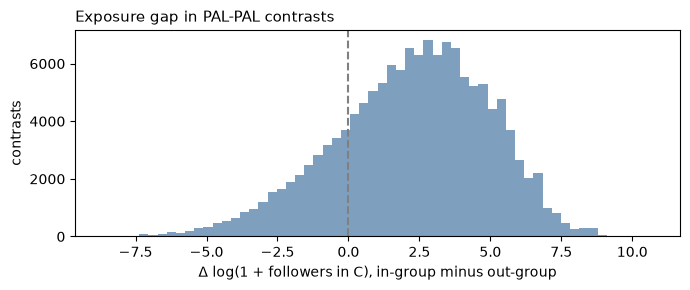

In [6]:
PAL = pooled(contrasts.filter(pl.col("side_pair") == "PAL-PAL"))
ISR = pooled(contrasts.filter(pl.col("side_pair") == "ISR-ISR"))

# The raw picture: in-group posts get most of the engagement, but their authors have far more
# followers in the community. This is why exposure is in the model.
d = r._design(PAL).filter((pl.col("in_reposts") + pl.col("out_reposts")) > 0)
print(f"PAL-PAL contrasts with any repost from C: {d.height:,}")
print(f"raw in-group share of reposts: {d['in_reposts'].sum() / (d['in_reposts'].sum() + d['out_reposts'].sum()):.0%}")
print(f"median followers in C: in-group {d['in_followers_c'].median():.0f}, out-group {d['out_followers_c'].median():.0f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(d["d_log_fc"].to_numpy(), bins=60, color="#7f9fbf")
ax.axvline(0, color="grey", ls="--")
ax.set_xlabel("Δ log(1 + followers in C), in-group minus out-group")
ax.set_ylabel("contrasts")
ax.set_title("Exposure gap in PAL-PAL contrasts", loc="left", fontsize=11)
plt.tight_layout()

## 4. Pre-registered model (confirmatory)

Saved by `uv run python -m bluesky_case_study.reception model` to `data/reception/model_PAL-PAL.parquet`. **The headline is the `primary` row for reposts.** Everything else is secondary or robustness.

`contrasts` counts contrasts with at least one engagement from C (the others carry no information in a conditional model).

In [7]:
model = pl.read_parquet(r.OUT_DIR / "model_PAL-PAL.parquet")
model.filter(~pl.col("analysis").str.starts_with("community")).select(
    "analysis", "outcome", "contrasts", "communities", "rate_ratio", "ci_low", "ci_high", "p")

analysis,outcome,contrasts,communities,rate_ratio,ci_low,ci_high,p
str,str,i64,i64,f64,f64,f64,f64
"""primary""","""reposts""",138060,27,1.05,0.87,1.27,0.59
"""primary""","""replies""",90333,28,1.07,0.92,1.24,0.40
"""primary""","""quotes""",25961,16,1.27,0.90,1.80,0.18
"""primary""","""neg_replies""",62956,21,1.06,0.89,1.27,0.52
"""exposure-matched (|d log followers_C| <= 1)""","""reposts""",24642,19,1.04,0.83,1.30,0.76
"""exposure-matched (|d log followers_C| <= 1)""","""replies""",18803,16,1.06,0.87,1.29,0.59
"""exposure-matched (|d log followers_C| <= 1)""","""quotes""",4489,11,1.28,0.80,2.06,0.31
"""exposure-matched (|d log followers_C| <= 1)""","""neg_replies""",12931,11,1.08,0.90,1.31,0.42
"""exposure as a spline (knots at quartiles)""","""reposts""",138060,27,0.99,0.80,1.23,0.96


<Axes: title={'left': 'Primary sample, all outcomes'}, xlabel='in-group / out-group rate ratio (log scale)'>

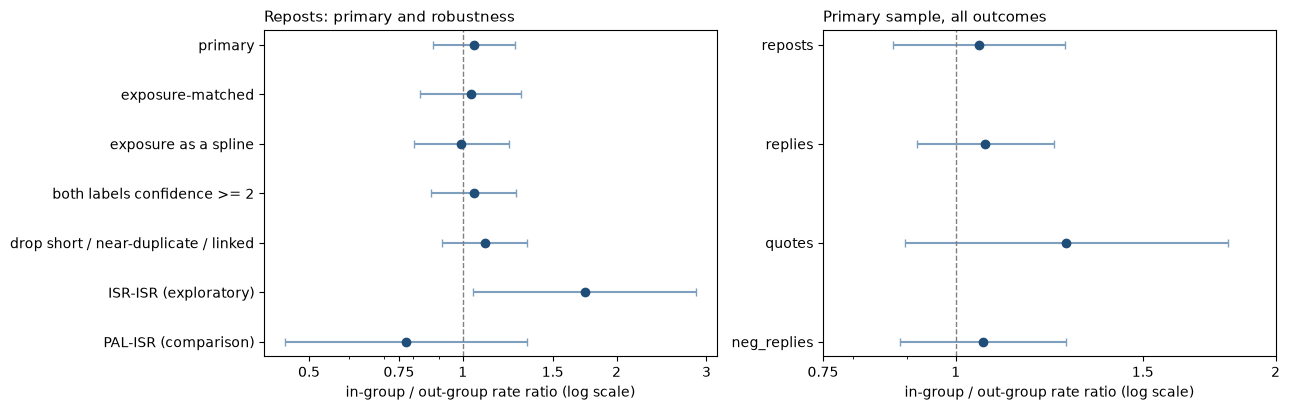

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
rep = model.filter((pl.col("outcome") == "reposts") & ~pl.col("analysis").str.starts_with("community"))
short = {"exposure-matched (|d log followers_C| <= 1)": "exposure-matched",
         "exposure as a spline (knots at quartiles)": "exposure as a spline",
         "PAL-ISR (opposite sides, comparison)": "PAL-ISR (comparison)"}
forest(rep.with_columns(pl.col("analysis").replace(short)), "Reposts: primary and robustness", ax=axes[0])
prim = model.filter(pl.col("analysis") == "primary")
forest(prim, "Primary sample, all outcomes", label_col="outcome", ax=axes[1])

**Reading.** The primary estimate is 1.05 (95% CI 0.87–1.27): no detectable in-group advantage for matched pro-Palestinian posts. The exposure-matched and spline checks agree, so the result doesn't hinge on how the exposure gap is modelled. Replies, quotes and negative-tone replies are also null. ISR–ISR is the one subset above 1 — see parts 6–8 before reading anything into it.

Per-community rows (each community with ≥ 1,000 PAL–PAL contrasts):

analysis,contrasts,rate_ratio,ci_low,ci_high,p
str,i64,f64,f64,f64,f64
"""community 4 only""",63213,1.20,0.95,1.52,0.13
"""community 1 only""",44641,1.20,0.84,1.70,0.32
"""community 6 only""",10773,2.78,1.95,3.96,0.00
"""community 2 only""",7065,1.27,0.56,2.85,0.57
"""community 20 only""",4587,1.39,0.66,2.92,0.39
"""community 3 only""",2224,0.75,0.17,3.37,0.71
"""community 9 only""",755,0.74,0.17,3.21,0.69
"""community 7 only""",172,0.04,0.00,1.17,0.06
"""community 40 only""",1552,28.77,4.29,192.66,0.00


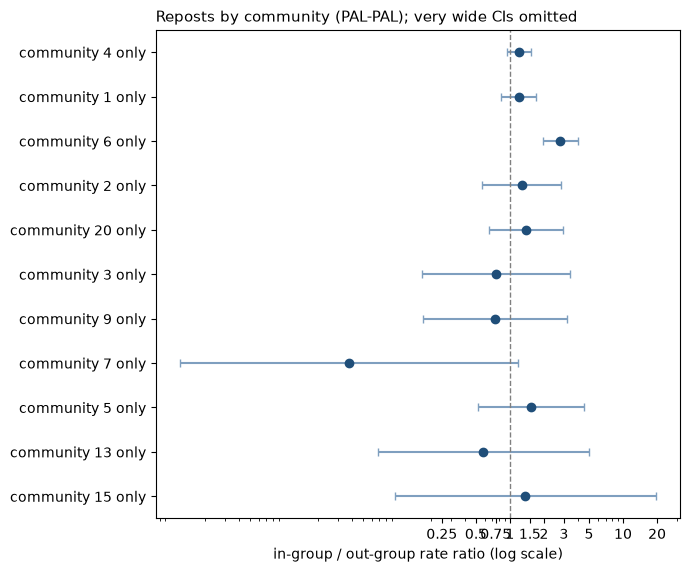

In [9]:
percomm = model.filter(pl.col("analysis").str.starts_with("community"))
forest(percomm.filter(pl.col("ci_high") < 50), "Reposts by community (PAL-PAL); very wide CIs omitted")
percomm.select("analysis", "contrasts", "rate_ratio", "ci_low", "ci_high", "p")

Communities 1 and 4 hold most of the data and are close to 1. **Community 6 is the exception** (part 9). The extreme ratios in small communities rest on a few dozen in-group authors and are not interpretable on their own.

## 5. Plan checks not in `model()`

The analysis plan lists three sensitivity checks that `model()` doesn't run: the seven-label match, similarity ≥ 0.85, and limiting hub posts. They're run here, plus two concentration checks. The cap of 5 contrasts per post was chosen after the model was run.

The seven-label match is identical to the primary for PAL–PAL (two `pro_palestinian` posts always share the seven-way label), so it isn't repeated.

analysis,outcome,contrasts,communities,rate_ratio,ci_low,ci_high,p
str,str,i64,i64,f64,f64,f64,f64
"""primary (reference)""","""reposts""",138060,27,1.05,0.87,1.27,0.59
"""similarity >= 0.85""","""reposts""",41827,24,1.01,0.76,1.35,0.94
"""max 5 contrasts per post per community""","""reposts""",47541,27,1.04,0.86,1.25,0.72
"""drop most-reposted in- and out-author""","""reposts""",135242,27,1.08,0.89,1.30,0.44
"""drop community 6""","""reposts""",127287,26,1.03,0.85,1.24,0.78


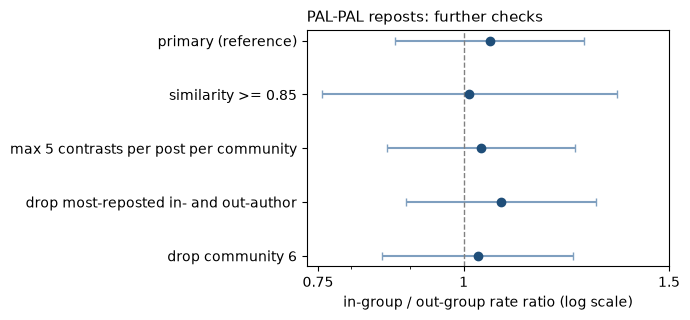

In [10]:
d = PAL.filter((pl.col("in_reposts") + pl.col("out_reposts")) > 0)
top_in = d.group_by("in_author").agg(pl.col("in_reposts").sum()).sort("in_reposts", descending=True)["in_author"][0]
top_out = d.group_by("out_author").agg(pl.col("out_reposts").sum()).sort("out_reposts", descending=True)["out_author"][0]
capped = (PAL.with_columns(pl.int_range(pl.len()).shuffle(seed=1).over("community", "in_post").alias("ri"),
                           pl.int_range(pl.len()).shuffle(seed=2).over("community", "out_post").alias("ro"))
             .filter((pl.col("ri") < 5) & (pl.col("ro") < 5)))
checks = table([
    fit(PAL, "primary (reference)"),
    fit(PAL.filter(pl.col("sim") >= 0.85), "similarity >= 0.85"),
    fit(capped, "max 5 contrasts per post per community"),
    fit(PAL.filter(~pl.col("in_author").is_in([top_in, top_out]) & ~pl.col("out_author").is_in([top_in, top_out])),
        "drop most-reposted in- and out-author"),
    fit(PAL.filter(pl.col("community") != 6), "drop community 6"),
])
forest(checks, "PAL-PAL reposts: further checks")
checks

In [11]:
# Engagement is concentrated in a few authors, which is why the CIs are wide for so many contrasts.
for who in ("in", "out"):
    g = d.group_by(f"{who}_author").agg(pl.col(f"{who}_reposts").sum().alias("ev")).sort("ev", descending=True)
    s = g["ev"].sum()
    print(f"{who}-group authors: {g.height:,}; top 10 hold {g['ev'][:10].sum() / s:.0%}, "
          f"top 100 hold {g['ev'][:100].sum() / s:.0%} of their reposts")

in-group authors: 9,409; top 10 hold 18%, top 100 hold 57% of their reposts
out-group authors: 12,157; top 10 hold 20%, top 100 hold 63% of their reposts


## 6. ISR–ISR hand check

Before reporting ISR–ISR, the plan required hand-coding about 50 random ISR–ISR pairs. 50 pairs were drawn uniformly (seed `isr-pairs-v1`, `isr_check.py`) and each post coded ISR / PAL / other, blind to author and community.

In [12]:
isr_check.score()

50 of 50 pairs coded
Both posts truly ISR (pair is a true stance match): 94% (95% CI 84%-98%, n=50)
At least one post truly PAL (opposite side):      0% (95% CI 0%-7%, n=50)
Posts truly ISR (per post):                       95% (95% CI 89%-98%, n=100)
Per-post sides: {'other': 5, 'ISR': 95}
Weighted by ISR-ISR contrasts (18 pairs): 89% both ISR (descriptive, no CI)


**Reading.** Both posts are truly pro-Israeli in 94% of pairs (95% CI 84–98%), and no post was pro-Palestinian. Pairing selects clearer posts than the test set (where only 75% of `pro_israeli` labels were right), because a post only enters a pair if it closely resembles another post with the same label. Label noise does not explain the ISR–ISR estimate. One coder did the check, and the sheet showed that both posts had the same label.

## 7. ISR–ISR breakdown (exploratory)

The ISR–ISR estimate (1.73 for reposts) was one of about 40 in the table. Is it broad or concentrated?

In [13]:
outs = ["reposts", "replies", "neg_replies"]
agg = [pl.len().alias("contrasts"), pl.col("in_author").n_unique().alias("in_authors")]
for o in outs:
    agg += [pl.col(f"in_{o}").sum().alias(f"in_{o}"), pl.col(f"out_{o}").sum().alias(f"out_{o}")]
ISR.group_by("community").agg(agg).sort("in_reposts", descending=True).head(8)

community,contrasts,in_authors,in_reposts,out_reposts,in_replies,out_replies,in_neg_replies,out_neg_replies
i32,u32,u32,u32,u32,u32,u32,u32,u32
1,22928,1623,6438,1442,8282,4649,6432,3376
6,12258,566,1480,494,3471,722,2459,454
4,6771,666,1321,234,2321,2411,1615,1791
5,4855,193,1302,98,315,51,72,13
7,405,20,137,16,30,1,2,0
20,655,43,127,4,182,8,113,4
12,451,25,67,0,8,0,0,0
15,377,18,42,1,36,1,6,0


analysis,outcome,contrasts,communities,rate_ratio,ci_low,ci_high,p
str,str,i64,i64,f64,f64,f64,f64
"""all ISR-ISR""","""reposts""",4968,13,1.73,1.05,2.86,0.03
"""only community 1""","""reposts""",3017,1,1.53,0.84,2.81,0.17
"""only community 6""","""reposts""",883,1,1.94,0.67,5.64,0.22
"""only community 4""","""reposts""",601,1,2.72,1.03,7.17,0.04
"""only community 5""","""reposts""",334,1,1.63,0.50,5.39,0.42
"""drop community 1""","""reposts""",1951,12,2.06,0.84,5.05,0.11
"""drop community 6""","""reposts""",4085,12,1.58,0.91,2.72,0.10
"""drop community 4""","""reposts""",4367,12,1.69,1.01,2.82,0.04
"""drop community 5""","""reposts""",4634,12,1.73,1.04,2.87,0.03


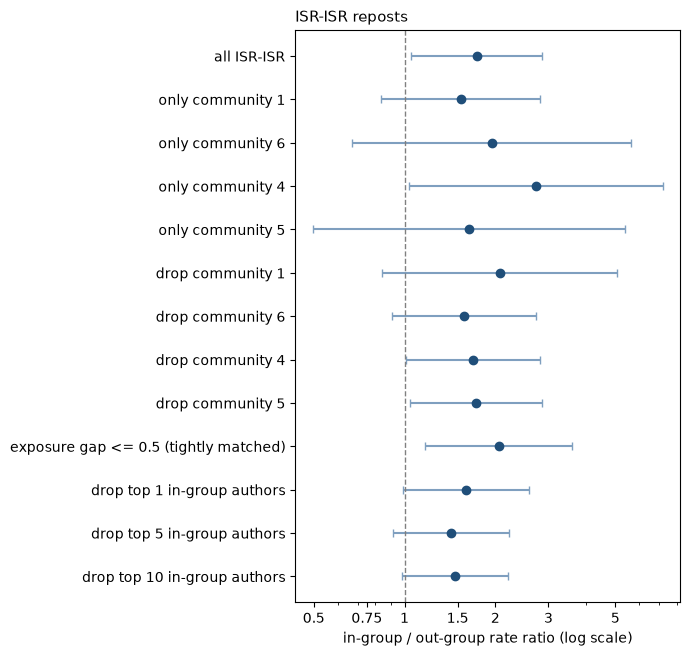

In [14]:
rows = [fit(ISR, "all ISR-ISR")]
for c in [1, 6, 4, 5]:
    rows.append(fit(ISR.filter(pl.col("community") == c), f"only community {c}"))
for c in [1, 6, 4, 5]:
    rows.append(fit(ISR.filter(pl.col("community") != c), f"drop community {c}"))
tight = r._design(ISR).filter(pl.col("d_log_fc").abs() <= 0.5)
rows.append(fit(tight, "exposure gap <= 0.5 (tightly matched)"))
top = (ISR.filter((pl.col("in_reposts") + pl.col("out_reposts")) > 0)
          .group_by("in_author").agg(pl.col("in_reposts").sum()).sort("in_reposts", descending=True)["in_author"])
for k in (1, 5, 10):
    rows.append(fit(ISR.filter(~pl.col("in_author").is_in(top[:k].implode())), f"drop top {k} in-group authors"))
isr_t = table(rows)
forest(isr_t.filter(pl.col("ci_high") < 50), "ISR-ISR reposts")
isr_t

In [15]:
# Replies and negative-tone replies: how much is community 6?
table([fit(ISR, "all ISR-ISR", o) for o in outs[1:]] +
      [fit(ISR.filter(pl.col("community") != 6), "drop community 6", o) for o in outs[1:]])

analysis,outcome,contrasts,communities,rate_ratio,ci_low,ci_high,p
str,str,i64,i64,f64,f64,f64,f64
"""all ISR-ISR""","""replies""",13603,17,1.52,1.10,2.09,0.01
"""all ISR-ISR""","""neg_replies""",10701,13,1.69,1.24,2.30,0.00
"""drop community 6""","""replies""",10871,16,1.15,0.88,1.50,0.32
"""drop community 6""","""neg_replies""",8628,12,1.30,0.99,1.70,0.06


**Reading.** The repost effect points the same way in every large community, and dropping any one community leaves it between about 1.6 and 2.1. It survives tight exposure matching (about 2×). It also partly rests on a few prolific authors: dropping the top 5 gives about 1.4, with a CI that includes 1. The reply effects are mostly community 6.

## 8. Exposure-slope sensitivity (exploratory)

The pre-registered model uses one exposure slope for all communities. Letting each community have its own slope is a reasonable alternative. It also allows a direct test of whether ISR–ISR differs from PAL–PAL.

In [16]:
pl.DataFrame([
    {"sample": "PAL-PAL", **fit_slopes(PAL)},
    {"sample": "ISR-ISR", **fit_slopes(ISR)},
    {"sample": "PAL-PAL + ISR-ISR (difference test)", **fit_slopes(pl.concat([PAL, ISR]), isr_term=True)},
])

sample,contrasts,in-group,ISR vs PAL
str,i64,str,str
"""PAL-PAL""",138060,"""1.25 (1.02-1.52), p=0.029""",null
"""ISR-ISR""",4968,"""2.15 (1.29-3.57), p=0.003""",null
"""PAL-PAL + ISR-ISR (difference test)""",143028,"""1.24 (1.02-1.51), p=0.030""","""1.33 (0.86-2.07), p=0.200"""


In [17]:
# The check that leans least on the slope: pairs whose authors have nearly the same followers in C.
table([
    fit(r._design(PAL).filter(pl.col("d_log_fc").abs() <= 0.5), "PAL-PAL, exposure gap <= 0.5"),
    fit(r._design(ISR).filter(pl.col("d_log_fc").abs() <= 0.5), "ISR-ISR, exposure gap <= 0.5"),
])

analysis,outcome,contrasts,communities,rate_ratio,ci_low,ci_high,p
str,str,i64,i64,f64,f64,f64,f64
"""PAL-PAL, exposure gap <= 0.5""","""reposts""",12101,17,0.96,0.75,1.24,0.78
"""ISR-ISR, exposure gap <= 0.5""","""reposts""",466,5,2.05,1.17,3.60,0.01


**Reading.**
- With a slope for each community, PAL–PAL rises to about 1.25. But exposure gaps are large (about 1.5–2.5 log units on average), so that estimate projects well beyond the data. The tightly matched check doesn't, and gives about 0.96. **The PAL–PAL null holds where it relies least on the model.**
- The direct test of ISR–ISR against PAL–PAL is not significant (ratio about 1.33, CI including 1). **The data cannot establish that the two sides differ.**

## 9. Community 6 (exploratory)

Community 6 is the one large community with a clear in-group effect for PAL–PAL (about 2.8×). What is it, and does the effect survive obvious alternative explanations?

In [18]:
BIG = [1, 2, 3, 4, 5, 6, 20]
comm = pl.read_parquet(DATA_DIR / "communities.parquet").select("user_id", "community")
corpus = (pl.read_parquet(DATA_DIR / "ip_corpus.parquet",
                          columns=["post_id", "user_id", "text", "instance", "repost_from"])
            .filter(pl.col("repost_from").is_null())
            .join(comm, on="user_id", how="left")
            .join(labels.select("post_id", "stance"), on="post_id", how="left"))

edges = (pl.read_parquet(DATA_DIR / "weighted_edges.parquet", columns=["src", "dst", "weight"])
           .filter(pl.col("src") != pl.col("dst"))
           .join(comm.rename({"user_id": "src", "community": "cs"}), on="src")
           .join(comm.rename({"user_id": "dst", "community": "cd"}), on="dst")
           .filter(pl.col("cs").is_in(BIG)))
internal = edges.group_by("cs").agg(
    (pl.col("weight").filter(pl.col("cs") == pl.col("cd")).sum() / pl.col("weight").sum()).alias("internal_share")
).rename({"cs": "community"})

side = (corpus.filter(pl.col("stance").is_not_null())
          .group_by("community").agg(
              pl.len().alias("labelled_posts"),
              pl.col("user_id").n_unique().alias("labelled_authors"),
              *[(pl.col("stance") == s).mean().alias(s) for s in ("pro_palestinian", "pro_israeli", "neutral_news")]))
(comm.group_by("community").len("members").join(internal, on="community").join(side, on="community")
     .filter(pl.col("community").is_in(BIG)).sort("members", descending=True))

community,members,internal_share,labelled_posts,labelled_authors,pro_palestinian,pro_israeli,neutral_news
i32,u32,f64,u32,u32,f64,f64,f64
1,208117,0.80,108960,14167,0.35,0.17,0.15
2,189352,0.79,4414,1751,0.62,0.04,0.03
3,152432,0.88,2968,991,0.61,0.05,0.02
4,149246,0.73,76074,8082,0.67,0.03,0.06
5,101134,0.95,4443,918,0.12,0.23,0.21
6,61152,0.73,24947,3683,0.34,0.12,0.24
20,7740,0.73,4260,803,0.57,0.04,0.11


In [19]:
# (labelled_posts above counts original I/P posts in at least one pair, i.e. with a stance label.)
# Words that set each community's I/P posts apart (log-odds vs all other communities).
# Only words used by at least 20 distinct authors, so single accounts' names and tags don't show up.
words = (corpus.filter(pl.col("community").is_not_null())
           .with_columns(pl.col("text").str.to_lowercase().str.replace_all(r"https?://\S+|@\S+", "")
                         .str.extract_all(r"#?[a-z][a-z'\-]{2,}").list.unique().alias("w"))
           .select("community", "user_id", "w").explode("w").filter(pl.col("w").is_not_null()))

def distinctive(c: int, k: int = 25) -> list[str]:
    a = words.filter(pl.col("community") == c).group_by("w").agg(pl.len().alias("a"), pl.col("user_id").n_unique().alias("authors"))
    b = words.filter(pl.col("community") != c).group_by("w").len("b")
    j = a.join(b, on="w", how="left").fill_null(0).filter((pl.col("a") >= 150) & (pl.col("authors") >= 20))
    j = j.with_columns(((pl.col("a") + 0.5) / j["a"].sum()).log().sub(((pl.col("b") + 0.5) / b["b"].sum()).log()).alias("lo"))
    return j.sort("lo", descending=True).head(k)["w"].to_list()

for c in (6, 1, 4, 5):
    print(f"community {c}: {', '.join(distinctive(c))}\n")

community 6: starmer, tories, sunak, archive, keir, tory, labour, mps, #russia, whilst, message, corbyn, translation, #hamas, ireland, #ukraine, politico, package, bbc, johnson, irish, defence, london, russian, ukrainian



community 1: menasky, stripes, elise, stefanik, faculty, ihl, newarab, friedman, foreignaffairs, washingtonpost, newyorker, theatlantic, campuses, genocidaires, campus, edu, latimes, one-state, greenblatt, nytimes, wapo, israel-news, lefty, zoom, combatants



community 4: palestineres, qudsnen, iof, nablus, comrades, palestinechronicle, youre, quds, vicinity, lmfao, yunis, martyred, martyrs, middleeasteye, cum, theyre, pages, warplanes, electronicintifada, al-aqsa, lmao, sperm, fuckin, aqsa, jenin



community 5: wurde, soll, bei, dazu, heute, einem, innen, jetzt, unter, krieg, einfach, machen, muss, einer, zum, sehr, vor, eine, wird, schon, damit, gro, auch, sich, nach



Community 6 is a **British and Irish politics** community that also follows the **Russia–Ukraine war** closely (translated Russian sources, defence news), with the most neutral news of the large communities. Its out-group authors in contrasts are mostly from community 4 (pro-Palestinian activists) and community 1 (US politics and media).

Does its in-group effect survive alternative explanations?

analysis,outcome,contrasts,communities,rate_ratio,ci_low,ci_high,p
str,str,i64,i64,f64,f64,f64,f64
"""community 6, as estimated""","""reposts""",10773,1,2.78,1.95,3.96,0.00
"""exposure-matched""","""reposts""",2397,1,3.10,1.99,4.83,0.00
"""drop top 10 in-group authors""","""reposts""",8983,1,2.38,1.67,3.39,0.00
"""drop 10 heaviest reposters""","""reposts""",9077,1,2.69,1.81,4.01,0.00
"""neither post mentions the UK""","""reposts""",10034,1,2.79,1.93,4.06,0.00
"""posted within 2 h of each other""","""reposts""",2707,1,2.66,1.82,3.89,0.00


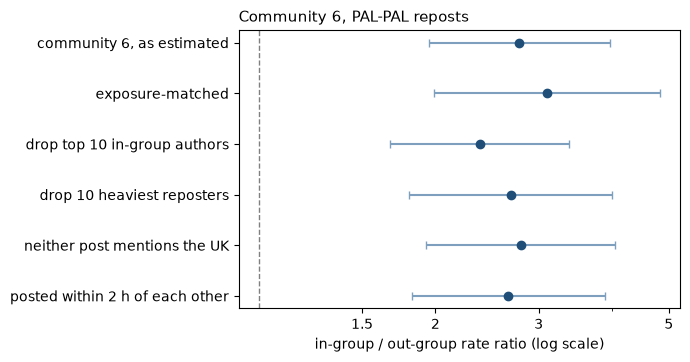

In [20]:
c6 = contrasts.filter((pl.col("community") == 6) & (pl.col("side_pair") == "PAL-PAL"))
reposts = pl.read_parquet(DATA_DIR / "ip_reposts.parquet").join(comm.rename({"user_id": "reposter_id"}), on="reposter_id", how="left")

# Top in-group authors and top reposters
d6 = c6.filter((pl.col("in_reposts") + pl.col("out_reposts")) > 0)
top_auth = d6.group_by("in_author").agg(pl.col("in_reposts").sum()).sort("in_reposts", descending=True)["in_author"]
r6 = reposts.filter((pl.col("community") == 6) & (pl.col("reposter_id") != pl.col("original_author_id")))
top_rep = (r6.filter(pl.col("original_post_id").is_in(d6["in_post"].unique().implode()))
             .group_by("reposter_id").len().sort("len", descending=True)["reposter_id"][:10])

def recount(df):
    # Recount reposts from community 6 without its 10 heaviest reposters of in-group posts.
    cnt = r6.filter(~pl.col("reposter_id").is_in(top_rep.implode())).group_by("original_post_id").len("n")
    return (df.join(cnt.rename({"original_post_id": "in_post", "n": "in_n"}), on="in_post", how="left")
              .join(cnt.rename({"original_post_id": "out_post", "n": "out_n"}), on="out_post", how="left")
              .with_columns(pl.col("in_n").fill_null(0).cast(pl.UInt32).alias("in_reposts"),
                            pl.col("out_n").fill_null(0).cast(pl.UInt32).alias("out_reposts")))

# UK framing and posting time
UK = r"(?i)\b(uk|britain|british|starmer|keir|labour|tory|tories|sunak|westminster|mps?|parliament|london|scotland|scottish|wales|welsh|ireland|irish|bbc|cameron|corbyn|nhs|downing)\b"
uk = corpus.select("post_id", pl.col("text").str.contains(UK).alias("uk"))
c6x = (c6.join(uk.rename({"post_id": "in_post", "uk": "in_uk"}), on="in_post", how="left")
         .join(uk.rename({"post_id": "out_post", "uk": "out_uk"}), on="out_post", how="left")
         .with_columns(pl.col("in_date").dt.hour().alias("hin"), pl.col("out_date").dt.hour().alias("hout"))
         .with_columns(pl.min_horizontal((pl.col("hin") - pl.col("hout")).abs(),
                                         24 - (pl.col("hin") - pl.col("hout")).abs()).alias("hgap")))

c6_t = table([
    fit(c6, "community 6, as estimated"),
    fit(r._design(c6).filter(pl.col("d_log_fc").abs() <= 1), "exposure-matched"),
    fit(c6.filter(~pl.col("in_author").is_in(top_auth[:10].implode())), "drop top 10 in-group authors"),
    fit(recount(c6), "drop 10 heaviest reposters"),
    fit(c6x.filter(~pl.col("in_uk").fill_null(False) & ~pl.col("out_uk").fill_null(False)), "neither post mentions the UK"),
    fit(c6x.filter(pl.col("hgap") <= 2), "posted within 2 h of each other"),
])
forest(c6_t, "Community 6, PAL-PAL reposts")
c6_t

In [21]:
# For contrast: community 6's ISR-ISR effect without its single most-reposted in-group author.
i6 = ISR.filter(pl.col("community") == 6)
top6 = (i6.filter((pl.col("in_reposts") + pl.col("out_reposts")) > 0)
          .group_by("in_author").agg(pl.col("in_reposts").sum()).sort("in_reposts", descending=True)["in_author"])
table([fit(i6, "community 6 ISR-ISR"), fit(i6.filter(pl.col("in_author") != top6[0]), "drop top in-group author")])

analysis,outcome,contrasts,communities,rate_ratio,ci_low,ci_high,p
str,str,i64,i64,f64,f64,f64,f64
"""community 6 ISR-ISR""","""reposts""",883,1,1.94,0.67,5.64,0.22
"""drop top in-group author""","""reposts""",813,1,1.51,0.64,3.55,0.35


**Reading.** Community 6's pro-Palestinian in-group effect (about 2.5–3×) is broad: it comes from hundreds of authors and reposters, and it survives exposure matching, dropping the heaviest accounts, removing UK-framed posts, and matching posting times. Its pro-Israeli estimate (about 1.9) is never distinguishable from 1, and one author produces about a quarter of its in-group reposts.

One plausible explanation is a community with its own national politics and news sources, which takes in Israel/Palestine content through its own commentators. Feed ranking and trust in particular authors aren't observed here and could also contribute. This is a case found after the fact.

## 10. Summary

**Confirmatory (pre-registered).**
- No detectable in-group advantage for matched pro-Palestinian posts: reposts 1.05 (95% CI 0.87–1.27). The result holds under every pre-registered robustness check and is closest to 1 when exposure is tightly matched (about 0.96).

**Exploratory.**
- **Pro-Israeli pairs** show an in-group advantage of about 1.5–2× that points the same way in every large community. The hand check confirms these pairs share a stance (94% both pro-Israeli). However, the effect partly depends on a few prolific authors, and it is not statistically distinguishable from the pro-Palestinian result.
- **Community 6** (British and Irish politics and Russia–Ukraine war news) shows a broad pro-Palestinian in-group effect of about 2.5–3× that survives every check here.

**Caveats.**
- Community membership comes from the same reply/repost/quote network the outcomes are counted from, so in-group authors are by construction already in the community's conversations.
- Stance labels are 76% accurate at side level on test. Errors don't depend on the author, so they should shrink differences rather than create them. The planned check of error rates by community is still to do.
- Likes have no liker ids, so they can't be attributed to communities and aren't analysed here.